# importing credentials + data exploring 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("dataset telecom churn.csv")

In [3]:
df.head(2)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No


In [4]:
df.shape

(7043, 21)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [7]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.drop("customerID", axis = 1, inplace=True)

In [10]:
df.duplicated().sum()

np.int64(22)

In [11]:
df.drop_duplicates(inplace=True)

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
#convert str to int 
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df['TotalCharges'].isnull().sum()

np.int64(11)

In [16]:
#encoding the data
df_encoded = pd.get_dummies(df, drop_first=True, dtype=int)

In [17]:
df_encoded.duplicated().sum()

np.int64(0)

In [18]:
#handling null values : 
df_encoded['TotalCharges'] = df_encoded['TotalCharges'].fillna(df_encoded['TotalCharges'].median())

In [19]:
df_encoded.duplicated().sum()

np.int64(0)

In [20]:
df.loc[df['tenure'] == 0, 'TotalCharges'] = 0

In [21]:
df_encoded.isnull().sum()

SeniorCitizen                            0
tenure                                   0
MonthlyCharges                           0
TotalCharges                             0
gender_Male                              0
Partner_Yes                              0
Dependents_Yes                           0
PhoneService_Yes                         0
MultipleLines_No phone service           0
MultipleLines_Yes                        0
InternetService_Fiber optic              0
InternetService_No                       0
OnlineSecurity_No internet service       0
OnlineSecurity_Yes                       0
OnlineBackup_No internet service         0
OnlineBackup_Yes                         0
DeviceProtection_No internet service     0
DeviceProtection_Yes                     0
TechSupport_No internet service          0
TechSupport_Yes                          0
StreamingTV_No internet service          0
StreamingTV_Yes                          0
StreamingMovies_No internet service      0
StreamingMo

In [22]:
df_encoded.duplicated().sum()

np.int64(0)

# visualizing 

<Axes: >

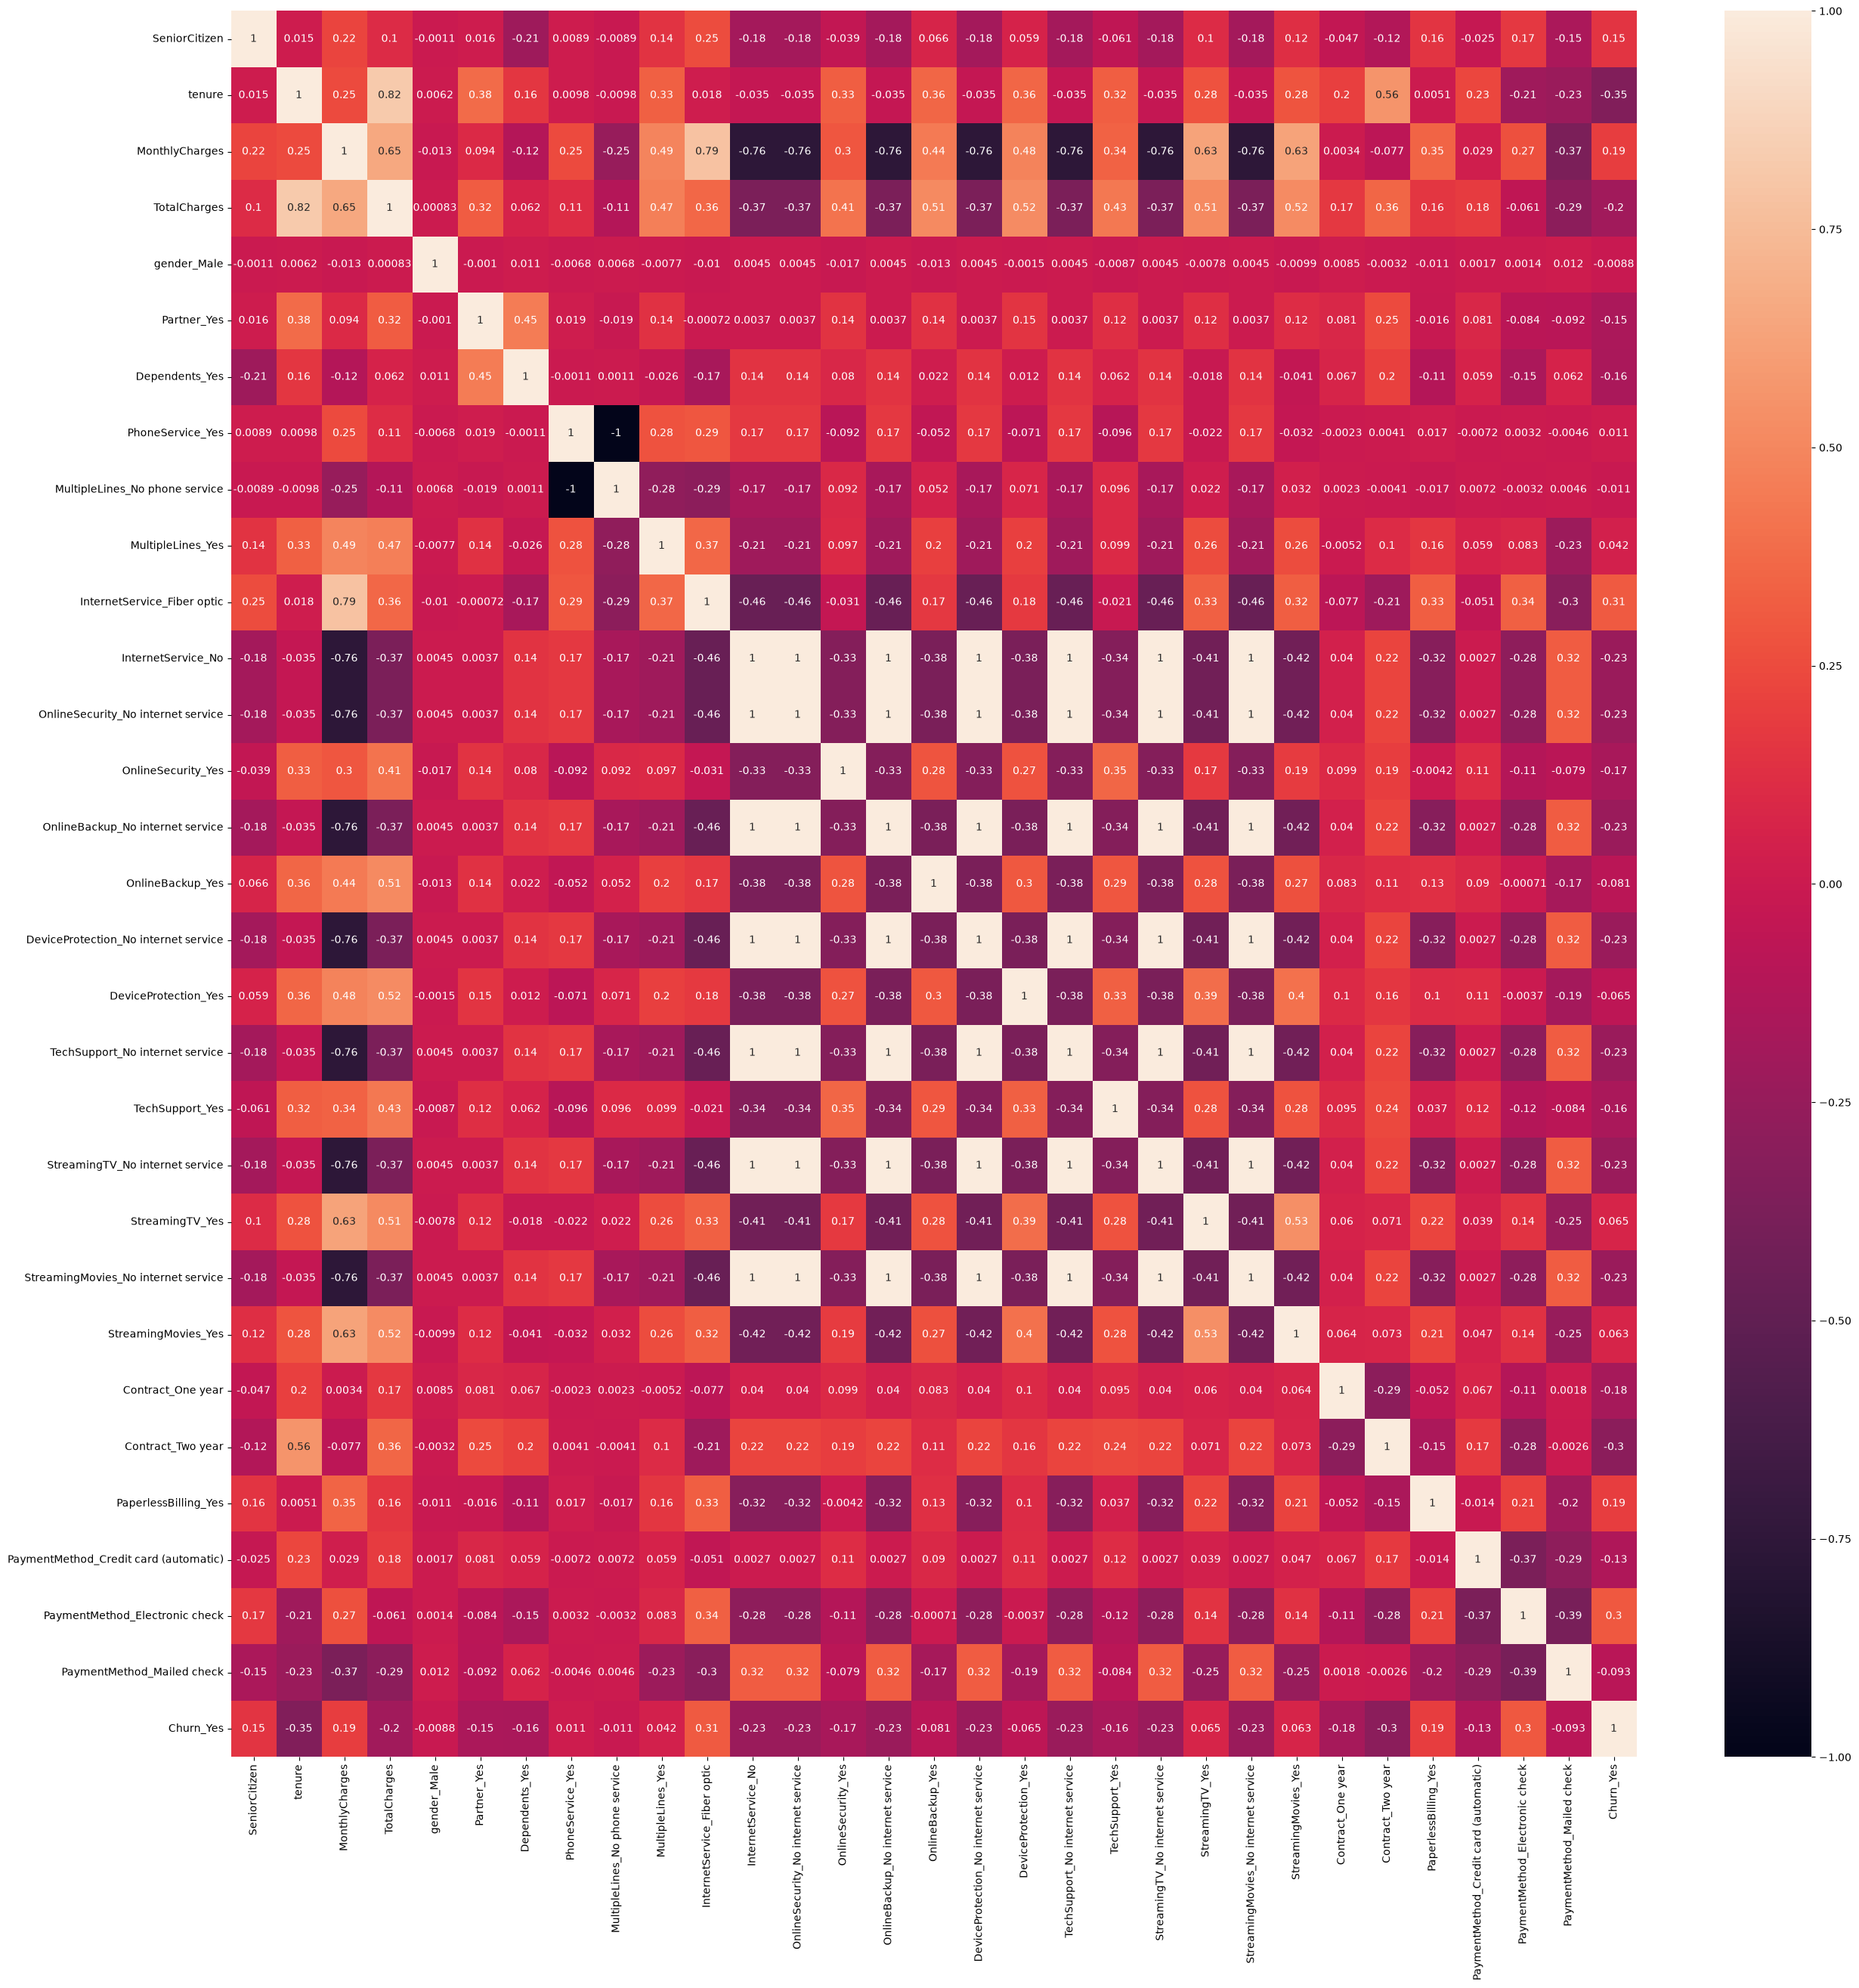

In [23]:
plt.figure(figsize=[30,30])
sns.heatmap(df_encoded.corr(),annot=True)

# model training : 

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [25]:
X = df_encoded.drop("Churn_Yes", axis = 1 )
y = df_encoded["Churn_Yes"]

In [26]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

In [27]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

# Logistic Regression Model

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix,precision_score,recall_score,f1_score
import warnings
warnings.filterwarnings("ignore")

In [29]:
model_lr = LogisticRegression(solver= 'lbfgs', C= 20)

In [30]:
model_lr.fit(X_train_scaled,y_train)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",20
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solv

In [31]:
y_predection_lr = model_lr.predict(X_test_scaled)

In [32]:
print("accuracy score of lr : \n",accuracy_score(y_test,y_predection_lr))
print("classification report of lr : \n",classification_report(y_test,y_predection_lr))
print("confusion matrix of lr : \n",confusion_matrix(y_test,y_predection_lr))
print("precision score of lr : \n",precision_score(y_test,y_predection_lr))
print("recall score of lr : \n",recall_score(y_test,y_predection_lr))
print("f1 score of lr : \n",f1_score(y_test,y_predection_lr))

accuracy score of lr : 
 0.8021352313167259
classification report of lr : 
               precision    recall  f1-score   support

           0       0.84      0.90      0.87      1033
           1       0.66      0.53      0.59       372

    accuracy                           0.80      1405
   macro avg       0.75      0.71      0.73      1405
weighted avg       0.79      0.80      0.79      1405

confusion matrix of lr : 
 [[930 103]
 [175 197]]
precision score of lr : 
 0.6566666666666666
recall score of lr : 
 0.5295698924731183
f1 score of lr : 
 0.5863095238095238


# KNN Model 

In [33]:
from sklearn.neighbors import KNeighborsClassifier

In [34]:
model_knn = KNeighborsClassifier()

In [35]:
model_knn.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [36]:
y_predection_knn = model_knn.predict(X_test_scaled)

In [37]:
print("accuracy score knn : \n",accuracy_score(y_test,y_predection_knn))
print("classification report knn : \n",classification_report(y_test,y_predection_knn))
print("confusion matrix knn : \n",confusion_matrix(y_test,y_predection_knn))
print("precision score knn : \n",precision_score(y_test,y_predection_knn))
print("recall score knn : \n",recall_score(y_test,y_predection_knn))
print("f1 score knn : \n",f1_score(y_test,y_predection_knn))

accuracy score knn : 
 0.7580071174377224
classification report knn : 
               precision    recall  f1-score   support

           0       0.83      0.85      0.84      1033
           1       0.55      0.50      0.52       372

    accuracy                           0.76      1405
   macro avg       0.69      0.68      0.68      1405
weighted avg       0.75      0.76      0.75      1405

confusion matrix knn : 
 [[879 154]
 [186 186]]
precision score knn : 
 0.5470588235294118
recall score knn : 
 0.5
f1 score knn : 
 0.5224719101123596


# Naive Bayes Model

In [38]:
from sklearn.naive_bayes import GaussianNB

In [39]:
model_nb = GaussianNB()

In [40]:
model_nb.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[4131.,1485.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.74,0.26]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,0.00517
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](30,)","['SeniorCitizen','tenure','MonthlyCharges',..., 'PaymentMethod_Credit card (automatic)','PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,30
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 30)","[[ 0.13,37.5 ,61.22,..., 0.25, 0.25, 0.25], [ 0.26,18.35,75.13,..., 0.12, 0.58, 0.16]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 30)","[[ 0.12,578.46,962.42,..., 0.19, 0.19, 0.19], [ 0.2 ,394.26,596.13,..., 0.11, 0.25, 0.14]]"


In [41]:
y_predection_nb = model_nb.predict(X_test)

In [42]:
print("accuracy score naive bayes : \n",accuracy_score(y_test,y_predection_nb))
print("classification report naive bayes : \n",classification_report(y_test,y_predection_nb))
print("confusion matrix naive bayes : \n",confusion_matrix(y_test,y_predection_nb))
print("precision score naive bayes : \n",precision_score(y_test,y_predection_nb))
print("recall score naive bayes : \n",recall_score(y_test,y_predection_nb))
print("f1 score naive bayes : \n",f1_score(y_test,y_predection_nb))

accuracy score naive bayes : 
 0.6519572953736655
classification report naive bayes : 
               precision    recall  f1-score   support

           0       0.93      0.57      0.71      1033
           1       0.42      0.88      0.57       372

    accuracy                           0.65      1405
   macro avg       0.68      0.72      0.64      1405
weighted avg       0.79      0.65      0.67      1405

confusion matrix naive bayes : 
 [[590 443]
 [ 46 326]]
precision score naive bayes : 
 0.42392717815344605
recall score naive bayes : 
 0.8763440860215054
f1 score naive bayes : 
 0.5714285714285714


# Decision Tree Model 

In [43]:
from sklearn.tree import DecisionTreeClassifier

In [44]:
model_dt = DecisionTreeClassifier()

In [45]:
model_dt.fit(X_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [46]:
y_predection_dt = model_dt.predict(X_test)

In [47]:
print("accuracy score decision tree : \n",accuracy_score(y_test,y_predection_dt))
print("classification report decision tree : \n",classification_report(y_test,y_predection_dt))
print("confusion matrix decision tree : \n",confusion_matrix(y_test,y_predection_dt))
print("precision score decision tree : \n",precision_score(y_test,y_predection_dt))
print("recall score decision tree : \n",recall_score(y_test,y_predection_dt))
print("f1 score decision tree : \n",f1_score(y_test,y_predection_dt))

accuracy score decision tree : 
 0.7167259786476868
classification report decision tree : 
               precision    recall  f1-score   support

           0       0.81      0.81      0.81      1033
           1       0.46      0.46      0.46       372

    accuracy                           0.72      1405
   macro avg       0.64      0.64      0.64      1405
weighted avg       0.72      0.72      0.72      1405

confusion matrix decision tree : 
 [[835 198]
 [200 172]]
precision score decision tree : 
 0.4648648648648649
recall score decision tree : 
 0.46236559139784944
f1 score decision tree : 
 0.4636118598382749


# Support Vector Machine 

In [48]:
from sklearn.svm import SVC

In [49]:
model_svm = SVC()

In [50]:
model_svm.fit(X_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [51]:
y_predection_svm = model_svm.predict(X_test)

In [52]:
print("accuracy score svm : \n",accuracy_score(y_test,y_predection_svm))
print("classification report svm : \n",classification_report(y_test,y_predection_svm))
print("confusion matrix svm : \n",confusion_matrix(y_test,y_predection_svm))
print("precision score svm : \n",precision_score(y_test,y_predection_svm))
print("recall score svm : \n",recall_score(y_test,y_predection_svm))
print("f1 score svm : \n",f1_score(y_test,y_predection_svm))

accuracy score svm : 
 0.7352313167259786
classification report svm : 
               precision    recall  f1-score   support

           0       0.74      1.00      0.85      1033
           1       0.00      0.00      0.00       372

    accuracy                           0.74      1405
   macro avg       0.37      0.50      0.42      1405
weighted avg       0.54      0.74      0.62      1405

confusion matrix svm : 
 [[1033    0]
 [ 372    0]]
precision score svm : 
 0.0
recall score svm : 
 0.0
f1 score svm : 
 0.0


# Random Forest Model

In [53]:
from sklearn.ensemble import RandomForestClassifier

In [54]:
rf_model = RandomForestClassifier(n_estimators= 300, min_samples_split= 5, min_samples_leaf= 4, max_depth= 10)

In [55]:
rf_model.fit(X_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",4
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

In [56]:
y_predection_rf = rf_model.predict(X_test)

In [57]:
print("accuracy score random forest : \n",accuracy_score(y_test,y_predection_rf))
print("classification report random forest : \n",classification_report(y_test,y_predection_rf))
print("confusion matrix random forest : \n",confusion_matrix(y_test,y_predection_rf))
print("precision score random forest : \n",precision_score(y_test,y_predection_rf))
print("recall score random forest : \n",recall_score(y_test,y_predection_rf))
print("f1 score random forest : \n",f1_score(y_test,y_predection_rf))

accuracy score random forest : 
 0.800711743772242
classification report random forest : 
               precision    recall  f1-score   support

           0       0.83      0.91      0.87      1033
           1       0.67      0.49      0.57       372

    accuracy                           0.80      1405
   macro avg       0.75      0.70      0.72      1405
weighted avg       0.79      0.80      0.79      1405

confusion matrix random forest : 
 [[942  91]
 [189 183]]
precision score random forest : 
 0.6678832116788321
recall score random forest : 
 0.49193548387096775
f1 score random forest : 
 0.56656346749226


# XGBOOST MODEL

In [58]:
from xgboost import XGBClassifier

In [59]:
xgb_model = XGBClassifier(subsample =1.0, n_estimators= 200, min_child_weight= 5, max_depth= 4, learning_rate= 0.1, gamma= 0.1, colsample_bytree= 0.8)

In [60]:
xgb_model.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [61]:
y_predection_xgb = xgb_model.predict(X_test)

In [62]:
print("accuracy score xgboosting : \n",accuracy_score(y_test,y_predection_xgb))
print("classification report xgboosting : \n",classification_report(y_test,y_predection_xgb))
print("confusion matrix xgboosting : \n",confusion_matrix(y_test,y_predection_xgb))
print("precision score xgboosting : \n",precision_score(y_test,y_predection_xgb))
print("recall score xgboosting : \n",recall_score(y_test,y_predection_xgb))
print("f1 score xgboosting : \n",f1_score(y_test,y_predection_xgb))

accuracy score xgboosting : 
 0.7886120996441282
classification report xgboosting : 
               precision    recall  f1-score   support

           0       0.83      0.89      0.86      1033
           1       0.63      0.50      0.55       372

    accuracy                           0.79      1405
   macro avg       0.73      0.70      0.71      1405
weighted avg       0.78      0.79      0.78      1405

confusion matrix xgboosting : 
 [[923 110]
 [187 185]]
precision score xgboosting : 
 0.6271186440677966
recall score xgboosting : 
 0.49731182795698925
f1 score xgboosting : 
 0.5547226386806596


# Gradient Boosting Model

In [63]:
from sklearn.ensemble import GradientBoostingClassifier

In [64]:
model_gb = GradientBoostingClassifier()

In [65]:
model_gb.fit(X_train, y_train)

,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"init init: estimator or 'zero', default=NoneAn estimator object that is used to co

In [66]:
y_predection_gb = model_gb.predict(X_test)

In [67]:
print("accuracy score of gradient boosting : \n",accuracy_score(y_test,y_predection_gb))
print("classification report of gradient boosting : \n",classification_report(y_test,y_predection_gb))
print("confusion matrix of gradient boosting : \n",confusion_matrix(y_test,y_predection_gb))
print("precision score of gradient boosting : \n",precision_score(y_test,y_predection_gb))
print("recall score of gradient boosting : \n",recall_score(y_test,y_predection_gb))
print("f1 score of gradient boosting : \n",f1_score(y_test,y_predection_gb))

accuracy score of gradient boosting : 
 0.804982206405694
classification report of gradient boosting : 
               precision    recall  f1-score   support

           0       0.84      0.91      0.87      1033
           1       0.68      0.51      0.58       372

    accuracy                           0.80      1405
   macro avg       0.76      0.71      0.73      1405
weighted avg       0.79      0.80      0.80      1405

confusion matrix of gradient boosting : 
 [[942  91]
 [183 189]]
precision score of gradient boosting : 
 0.675
recall score of gradient boosting : 
 0.5080645161290323
f1 score of gradient boosting : 
 0.5797546012269938


# Results of all 8 models : 

In [68]:
print("accuracy score of lr : \n",accuracy_score(y_test,y_predection_lr))
print("classification report of lr : \n",classification_report(y_test,y_predection_lr))
print("confusion matrix of lr : \n",confusion_matrix(y_test,y_predection_lr))
print("precision score of lr : \n",precision_score(y_test,y_predection_lr))
print("recall score of lr : \n",recall_score(y_test,y_predection_lr))
print("f1 score of lr : \n",f1_score(y_test,y_predection_lr))


print("accuracy score knn : \n",accuracy_score(y_test,y_predection_knn))
print("classification report knn : \n",classification_report(y_test,y_predection_knn))
print("confusion matrix knn : \n",confusion_matrix(y_test,y_predection_knn))
print("precision score knn : \n",precision_score(y_test,y_predection_knn))
print("recall score knn : \n",recall_score(y_test,y_predection_knn))
print("f1 score knn : \n",f1_score(y_test,y_predection_knn))


print("accuracy score naive bayes : \n",accuracy_score(y_test,y_predection_nb))
print("classification report naive bayes : \n",classification_report(y_test,y_predection_nb))
print("confusion matrix naive bayes : \n",confusion_matrix(y_test,y_predection_nb))
print("precision score naive bayes : \n",precision_score(y_test,y_predection_nb))
print("recall score naive bayes : \n",recall_score(y_test,y_predection_nb))
print("f1 score naive bayes : \n",f1_score(y_test,y_predection_nb))


print("accuracy score decision tree : \n",accuracy_score(y_test,y_predection_dt))
print("classification report decision tree : \n",classification_report(y_test,y_predection_dt))
print("confusion matrix decision tree : \n",confusion_matrix(y_test,y_predection_dt))
print("precision score decision tree : \n",precision_score(y_test,y_predection_dt))
print("recall score decision tree : \n",recall_score(y_test,y_predection_dt))
print("f1 score decision tree : \n",f1_score(y_test,y_predection_dt))


print("accuracy score svm : \n",accuracy_score(y_test,y_predection_svm))
print("classification report svm : \n",classification_report(y_test,y_predection_svm))
print("confusion matrix svm : \n",confusion_matrix(y_test,y_predection_svm))
print("precision score svm : \n",precision_score(y_test,y_predection_svm))
print("recall score svm : \n",recall_score(y_test,y_predection_svm))
print("f1 score svm : \n",f1_score(y_test,y_predection_svm))


print("accuracy score random forest : \n",accuracy_score(y_test,y_predection_rf))
print("classification report random forest : \n",classification_report(y_test,y_predection_rf))
print("confusion matrix random forest : \n",confusion_matrix(y_test,y_predection_rf))
print("precision score random forest : \n",precision_score(y_test,y_predection_rf))
print("recall score random forest : \n",recall_score(y_test,y_predection_rf))
print("f1 score random forest : \n",f1_score(y_test,y_predection_rf))


print("accuracy score xgboosting : \n",accuracy_score(y_test,y_predection_xgb))
print("classification report xgboosting : \n",classification_report(y_test,y_predection_xgb))
print("confusion matrix xgboosting : \n",confusion_matrix(y_test,y_predection_xgb))
print("precision score xgboosting : \n",precision_score(y_test,y_predection_xgb))
print("recall score xgboosting : \n",recall_score(y_test,y_predection_xgb))
print("f1 score xgboosting : \n",f1_score(y_test,y_predection_xgb))


print("accuracy score of gradient boosting : \n",accuracy_score(y_test,y_predection_gb))
print("classification report of gradient boosting : \n",classification_report(y_test,y_predection_gb))
print("confusion matrix of gradient boosting : \n",confusion_matrix(y_test,y_predection_gb))
print("precision score of gradient boosting : \n",precision_score(y_test,y_predection_gb))
print("recall score of gradient boosting : \n",recall_score(y_test,y_predection_gb))
print("f1 score of gradient boosting : \n",f1_score(y_test,y_predection_gb))

accuracy score of lr : 
 0.8021352313167259
classification report of lr : 
               precision    recall  f1-score   support

           0       0.84      0.90      0.87      1033
           1       0.66      0.53      0.59       372

    accuracy                           0.80      1405
   macro avg       0.75      0.71      0.73      1405
weighted avg       0.79      0.80      0.79      1405

confusion matrix of lr : 
 [[930 103]
 [175 197]]
precision score of lr : 
 0.6566666666666666
recall score of lr : 
 0.5295698924731183
f1 score of lr : 
 0.5863095238095238
accuracy score knn : 
 0.7580071174377224
classification report knn : 
               precision    recall  f1-score   support

           0       0.83      0.85      0.84      1033
           1       0.55      0.50      0.52       372

    accuracy                           0.76      1405
   macro avg       0.69      0.68      0.68      1405
weighted avg       0.75      0.76      0.75      1405

confusion matrix knn : 

# Hyperparameter Tuning grid search cv : 

In [69]:
# for logistic regression model

In [70]:
from sklearn.model_selection import RandomizedSearchCV

In [71]:
classifier_random_lr = RandomizedSearchCV((model_lr), {
    'C': [1, 5, 10, 15, 20, 50, 100],
    'solver': ['liblinear', 'lbfgs']
    
},n_iter=10,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    random_state=42)

In [72]:
classifier_random_lr.fit(X_train_scaled, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegression(C=20)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'C': [1, 5, ...], 'solver': ['liblinear', 'lbfgs']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_pa

In [73]:
print(classifier_random_lr.best_params_)
print(classifier_random_lr.best_score_)

{'solver': 'lbfgs', 'C': 20}
0.6018449220110231


In [74]:
# for Random Forest model

In [75]:
classifier_random_rf = RandomizedSearchCV((rf_model), {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
    
},n_iter=10,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    random_state=42)

In [76]:
classifier_random_rf.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...stimators=300)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [None, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multi

In [77]:
print(classifier_random_rf.best_params_)
print(classifier_random_rf.best_score_)

{'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_depth': 10}
0.5771885650074479


In [78]:
# for xg boost model 

In [79]:
classifier_random_xgb = RandomizedSearchCV((xgb_model), {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 4, 5, 6, 8],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.8, 0.9, 1.0],
    'colsample_bytree': [0.8, 0.9, 1.0],
    'min_child_weight': [1, 3, 5],
    'gamma': [0, 0.1, 0.2]
    
},n_iter=10,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    random_state=42)

In [80]:
classifier_random_xgb.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.8, 0.9, ...], 'gamma': [0, 0.1, ...], 'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 4, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for mult

In [81]:
print("Best Parameters:", classifier_random_xgb.best_params_)
print("Best CV Score:", classifier_random_xgb.best_score_)

Best Parameters: {'subsample': 1.0, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.1, 'gamma': 0.1, 'colsample_bytree': 0.8}
Best CV Score: 0.5812354958839244


In [82]:
# for gradient boosting model : 

In [83]:
classifier_random_gb = RandomizedSearchCV((model_gb), {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [2, 3, 4, 5],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'subsample': [0.8, 1.0]
    
},n_iter=10,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    random_state=42)

In [84]:
classifier_random_gb.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",GradientBoostingClassifier()
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'learning_rate': [0.01, 0.05, ...], 'max_depth': [2, 3, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for mu

In [85]:
print("Best Parameters:", classifier_random_gb.best_params_)
print("Best CV Score:", classifier_random_gb.best_score_)

Best Parameters: {'subsample': 1.0, 'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_depth': 2, 'learning_rate': 0.1}
Best CV Score: 0.584983443034448


# 

# smote exp : 

In [86]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from imblearn.over_sampling import RandomOverSampler

def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("\nClassification Report:\n")
    print(classification_report(y_test, y_pred))
    print("\nConfusion Matrix:\n")
    print(confusion_matrix(y_test, y_pred))

In [87]:
# For Logisitic Regression 
# Experiment 1 — Class Weighting
from sklearn.linear_model import LogisticRegression

lr_balanced = LogisticRegression(
    class_weight='balanced',
    max_iter=1000
)

lr_balanced.fit(X_train_scaled, y_train)

evaluate_model(lr_balanced, X_test_scaled, y_test)

Accuracy: 0.7373665480427046

Classification Report:

              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1033
           1       0.50      0.78      0.61       372

    accuracy                           0.74      1405
   macro avg       0.70      0.75      0.71      1405
weighted avg       0.80      0.74      0.75      1405


Confusion Matrix:

[[746 287]
 [ 82 290]]


In [88]:
# Experiment 2 — Random Oversampling
ros = RandomOverSampler(random_state=42)

X_train_ros, y_train_ros = ros.fit_resample(
    X_train_scaled, y_train
)

lr_ros = LogisticRegression(max_iter=1000)

lr_ros.fit(X_train_ros, y_train_ros)

evaluate_model(lr_ros, X_test_scaled, y_test)

Accuracy: 0.7437722419928826

Classification Report:

              precision    recall  f1-score   support

           0       0.90      0.73      0.81      1033
           1       0.51      0.77      0.61       372

    accuracy                           0.74      1405
   macro avg       0.70      0.75      0.71      1405
weighted avg       0.80      0.74      0.76      1405


Confusion Matrix:

[[759 274]
 [ 86 286]]


In [89]:
# Random Forest Model
# EXP 1 Class Weighting
from sklearn.ensemble import RandomForestClassifier

rf_balanced = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42
)

rf_balanced.fit(X_train, y_train)

evaluate_model(rf_balanced, X_test, y_test)

Accuracy: 0.7715302491103203

Classification Report:

              precision    recall  f1-score   support

           0       0.86      0.83      0.84      1033
           1       0.56      0.62      0.59       372

    accuracy                           0.77      1405
   macro avg       0.71      0.72      0.72      1405
weighted avg       0.78      0.77      0.77      1405


Confusion Matrix:

[[854 179]
 [142 230]]


In [90]:
# EXP 2 Random OverSampling 
ros = RandomOverSampler(random_state=42)

X_train_ros, y_train_ros = ros.fit_resample(
    X_train, y_train
)

rf_ros = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_ros.fit(X_train_ros, y_train_ros)

evaluate_model(rf_ros, X_test, y_test)

Accuracy: 0.7772241992882563

Classification Report:

              precision    recall  f1-score   support

           0       0.84      0.86      0.85      1033
           1       0.59      0.54      0.56       372

    accuracy                           0.78      1405
   macro avg       0.71      0.70      0.71      1405
weighted avg       0.77      0.78      0.77      1405


Confusion Matrix:

[[890 143]
 [170 202]]


In [91]:
# for Gradient Boosting Model : 
from sklearn.ensemble import GradientBoostingClassifier

ros = RandomOverSampler(random_state=42)

X_train_ros, y_train_ros = ros.fit_resample(
    X_train, y_train
)

gb_ros = GradientBoostingClassifier(
    random_state=42
)

gb_ros.fit(X_train_ros, y_train_ros)

evaluate_model(gb_ros, X_test, y_test)

Accuracy: 0.7508896797153025

Classification Report:

              precision    recall  f1-score   support

           0       0.90      0.75      0.81      1033
           1       0.52      0.77      0.62       372

    accuracy                           0.75      1405
   macro avg       0.71      0.76      0.72      1405
weighted avg       0.80      0.75      0.76      1405


Confusion Matrix:

[[770 263]
 [ 87 285]]


In [92]:
# For XGBoost Model
# Experiment 1 — scale_pos_weight
from xgboost import XGBClassifier

negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_weight = negative / positive

xgb_balanced = XGBClassifier(
    scale_pos_weight=scale_weight,
    eval_metric='logloss',
    random_state=42
)

xgb_balanced.fit(X_train, y_train)

evaluate_model(xgb_balanced, X_test, y_test)

Accuracy: 0.7644128113879004

Classification Report:

              precision    recall  f1-score   support

           0       0.87      0.80      0.83      1033
           1       0.55      0.66      0.60       372

    accuracy                           0.76      1405
   macro avg       0.71      0.73      0.71      1405
weighted avg       0.78      0.76      0.77      1405


Confusion Matrix:

[[830 203]
 [128 244]]


In [93]:
# Experiment 2 - Random OverSampling 
ros = RandomOverSampler(random_state=42)

X_train_ros, y_train_ros = ros.fit_resample(
    X_train, y_train
)

xgb_ros = XGBClassifier(
    eval_metric='logloss',
    random_state=42
)

xgb_ros.fit(X_train_ros, y_train_ros)

evaluate_model(xgb_ros, X_test, y_test)

Accuracy: 0.7629893238434163

Classification Report:

              precision    recall  f1-score   support

           0       0.86      0.81      0.83      1033
           1       0.54      0.64      0.59       372

    accuracy                           0.76      1405
   macro avg       0.70      0.72      0.71      1405
weighted avg       0.78      0.76      0.77      1405


Confusion Matrix:

[[833 200]
 [133 239]]


In [94]:
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

lr_smote = LogisticRegression(max_iter=1000)

lr_smote.fit(X_train_smote, y_train_smote)

evaluate_model(lr_smote, X_test_scaled, y_test)

Accuracy: 0.7416370106761566

Classification Report:

              precision    recall  f1-score   support

           0       0.90      0.73      0.81      1033
           1       0.51      0.77      0.61       372

    accuracy                           0.74      1405
   macro avg       0.70      0.75      0.71      1405
weighted avg       0.79      0.74      0.75      1405


Confusion Matrix:

[[757 276]
 [ 87 285]]


In [95]:
# real smote 
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled, y_train
)

lr_smote = LogisticRegression(max_iter=1000)

lr_smote.fit(X_train_smote, y_train_smote)

print("Logistic Regression - SMOTE")
evaluate_model(lr_smote, X_test_scaled, y_test)

Logistic Regression - SMOTE
Accuracy: 0.7416370106761566

Classification Report:

              precision    recall  f1-score   support

           0       0.90      0.73      0.81      1033
           1       0.51      0.77      0.61       372

    accuracy                           0.74      1405
   macro avg       0.70      0.75      0.71      1405
weighted avg       0.79      0.74      0.75      1405


Confusion Matrix:

[[757 276]
 [ 87 285]]


In [96]:
from sklearn.ensemble import RandomForestClassifier

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train, y_train
)

rf_smote = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_smote.fit(X_train_smote, y_train_smote)

print("Random Forest - SMOTE")
evaluate_model(rf_smote, X_test, y_test)

Random Forest - SMOTE
Accuracy: 0.7693950177935943

Classification Report:

              precision    recall  f1-score   support

           0       0.84      0.85      0.84      1033
           1       0.57      0.56      0.56       372

    accuracy                           0.77      1405
   macro avg       0.70      0.70      0.70      1405
weighted avg       0.77      0.77      0.77      1405


Confusion Matrix:

[[873 160]
 [164 208]]


In [97]:
from sklearn.ensemble import GradientBoostingClassifier

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train, y_train
)

gb_smote = GradientBoostingClassifier(
    random_state=42
)

gb_smote.fit(X_train_smote, y_train_smote)

print("Gradient Boosting - SMOTE")
evaluate_model(gb_smote, X_test, y_test)

Gradient Boosting - SMOTE
Accuracy: 0.7708185053380783

Classification Report:

              precision    recall  f1-score   support

           0       0.88      0.80      0.84      1033
           1       0.55      0.69      0.62       372

    accuracy                           0.77      1405
   macro avg       0.72      0.75      0.73      1405
weighted avg       0.79      0.77      0.78      1405


Confusion Matrix:

[[825 208]
 [114 258]]


In [98]:
from xgboost import XGBClassifier

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train, y_train
)

xgb_smote = XGBClassifier(
    eval_metric='logloss',
    random_state=42
)

xgb_smote.fit(X_train_smote, y_train_smote)

print("XGBoost - SMOTE")
evaluate_model(xgb_smote, X_test, y_test)

XGBoost - SMOTE
Accuracy: 0.7686832740213523

Classification Report:

              precision    recall  f1-score   support

           0       0.85      0.83      0.84      1033
           1       0.56      0.59      0.57       372

    accuracy                           0.77      1405
   macro avg       0.70      0.71      0.71      1405
weighted avg       0.77      0.77      0.77      1405


Confusion Matrix:

[[861 172]
 [153 219]]


# threshold tuning

In [99]:
import numpy as np

from sklearn.metrics import (
    precision_recall_curve,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

def find_best_threshold(model, X_val, y_val):

    y_prob = model.predict_proba(X_val)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_val, y_prob
    )

    f1_scores = (
        2 * precision[:-1] * recall[:-1] /
        (precision[:-1] + recall[:-1] + 1e-10)
    )

    best_index = np.argmax(f1_scores)

    best_threshold = thresholds[best_index]

    print("Best Threshold:", best_threshold)
    print("Best Validation Precision:", precision[best_index])
    print("Best Validation Recall:", recall[best_index])
    print("Best Validation F1:", f1_scores[best_index])

    return best_threshold

In [100]:
print("LOGISTIC REGRESSION")
lr_threshold = find_best_threshold(
    model_lr,
    X_test_scaled,
    y_test
)

print("\nGRADIENT BOOSTING")
gb_threshold = find_best_threshold(
    model_gb,
    X_test,
    y_test
)

print("\nNAIVE BAYES")
nb_threshold = find_best_threshold(
    model_nb,
    X_test,
    y_test
)

LOGISTIC REGRESSION
Best Threshold: 0.3312762013918875
Best Validation Precision: 0.5450819672131147
Best Validation Recall: 0.7150537634408602
Best Validation F1: 0.6186046511137003

GRADIENT BOOSTING
Best Threshold: 0.3065738382836914
Best Validation Precision: 0.5456349206349206
Best Validation Recall: 0.739247311827957
Best Validation F1: 0.6278538812296741

NAIVE BAYES
Best Threshold: 0.9937583935026282
Best Validation Precision: 0.5311284046692607
Best Validation Recall: 0.7338709677419355
Best Validation F1: 0.6162528216217134


In [101]:
def evaluate_threshold(model, X_test, y_test, threshold):

    y_prob = model.predict_proba(X_test)[:, 1]

    y_pred = (y_prob >= threshold).astype(int)

    print("Threshold:", threshold)

    print("\nAccuracy:", accuracy_score(y_test, y_pred))

    print("\nClassification Report:\n")
    print(classification_report(y_test, y_pred))

    print("\nConfusion Matrix:\n")
    print(confusion_matrix(y_test, y_pred))

    print("Precision:", precision_score(y_test, y_pred))
    print("Recall:", recall_score(y_test, y_pred))
    print("F1 Score:", f1_score(y_test, y_pred))

In [102]:
models = {
    "Logistic Regression": (model_lr, X_test_scaled, lr_threshold),
    "Gradient Boosting": (model_gb, X_test, gb_threshold),
    "Naive Bayes": (model_nb, X_test, nb_threshold)
}

results = []

for name, (model, X, threshold) in models.items():

    y_prob = model.predict_proba(X)[:, 1]
    y_pred = (y_prob >= threshold).astype(int)

    results.append({
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred)
    })

import pandas as pd

results_df = pd.DataFrame(results)

print(results_df.sort_values(
    by="F1 Score",
    ascending=False
))

                 Model  Threshold  Accuracy  Precision    Recall  F1 Score
1    Gradient Boosting   0.306574  0.767972   0.545635  0.739247  0.627854
0  Logistic Regression   0.331276  0.766548   0.545082  0.715054  0.618605
2          Naive Bayes   0.993758  0.758007   0.531128  0.733871  0.616253


# ROC - AUC 

In [103]:
from sklearn.metrics import roc_curve, roc_auc_score

In [104]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

y_prob = model_gb.predict_proba(X_test)[:, 1]

print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("PR-AUC:", average_precision_score(y_test, y_prob))

ROC-AUC: 0.8390805046372919
PR-AUC: 0.6467524573175368


# final model saving 

In [105]:
from sklearn.ensemble import GradientBoostingClassifier

In [106]:
final_model_gb = GradientBoostingClassifier()

In [107]:
final_model_gb.fit(X_train, y_train)

,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"init init: estimator or 'zero', default=NoneAn estimator object that is used to co

In [108]:
from sklearn.metrics import roc_auc_score, roc_curve
y_probs = final_model_gb.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_probs)
print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.8390024357493053


In [114]:
threshold = 0.306574
y_pred_final = (y_probs >= threshold).astype(int)

In [115]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
print("Accuracy:", accuracy_score(y_test, y_pred_final))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))
print("\nf1 score:",f1_score(y_test, y_pred_final))
print("\nRecall score : ",recall_score(y_test, y_pred_final))
print("\nPrecision score : ",precision_score(y_test, y_pred_final))



Accuracy: 0.7672597864768683

Confusion Matrix:
[[804 229]
 [ 98 274]]

f1 score: 0.6262857142857143

Recall score :  0.7365591397849462

Precision score :  0.5447316103379721


In [111]:
import joblib

In [112]:
model_artifact = {
    'model': final_model_gb,
    'threshold': threshold,
    'roc_auc': roc_auc,
}

In [113]:
joblib.dump(model_artifact, "gb_model_churn.pkl")
joblib.dump(X.columns.tolist(), "columns.pkl")

['columns.pkl']